# Baseline CNN with fixed hyperparameters

This notebook establishes a reference experiment. The settings below are starting choices, not universally optimal values. Hyperparameter comparisons belong to a later experiment. The test set is reserved for final evaluation.

Run all cells in order to create and train a fresh model.

## 1. Imports

In [12]:
#%load_ext autoreload
#%autoreload 2
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import tensorflow as tf

keras = tf.keras
layers = keras.layers
Sequential = keras.Sequential

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.load_metadata import load_metadata
from src.split_dataset import split
from src.input_pipeline import build_dataset


## 2. Fixed configuration

Adam uses a learning rate of 0.001. Keep the existing architecture and writer split for this baseline. Fixing the seed improves reproducibility but does not guarantee identical results on every platform.

In [13]:
SEED = 12
BATCH_SIZE = 32
LEARNING_RATE = 0.001
FILTERS = (32, 64)
KERNEL_SIZE = 3
DENSE_UNITS = 128
MAX_EPOCHS = 10
PATIENCE = 3
INPUT_SHAPE = (63, 64, 1)

keras.utils.set_random_seed(SEED)

## 3. Data and shared labels

Pixels are already normalized by the input pipeline. Do not add another rescaling layer.

In [14]:
metadata = load_metadata()

df_train, df_valid, df_test = split(
    metadata,
    training=0.7,
    validation=0.15,
    test=0.15,
    seed=SEED,
)

unique_char = sorted(metadata["char"].unique())
char_dic = {char: index for index, char in enumerate(unique_char)}
df_train["label"] = df_train["char"].map(char_dic)
df_valid["label"] = df_valid["char"].map(char_dic)
df_test["label"] = df_test["char"].map(char_dic)


train_ds = build_dataset(df_train, batch_size=BATCH_SIZE, training=True, seed=SEED)
val_ds = build_dataset(df_valid, batch_size=BATCH_SIZE, training=False)

## 4. Model

In [15]:
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

model = keras.Sequential([
    layers.Input(shape=INPUT_SHAPE),
    layers.Conv2D(FILTERS[0], KERNEL_SIZE, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(FILTERS[1], KERNEL_SIZE, activation="relu"),
    layers.Flatten(),
    layers.Dense(DENSE_UNITS, activation="relu"),
    layers.Dense(len(unique_char), activation="softmax"),
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 61, 62, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 30, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 51968)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,652,032 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 48)             │         6,192 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,677,040 (25.47 MB)

 Trainable params: 6,677,040 (25.47 MB)

 Non-trainable params: 0 (0.00 B)

## 5. Check a batch without updating weights

In [16]:
for images, labels in train_ds.take(1):
    predictions = model(images, training=False)
    print("Images:", images.shape)
    print("Labels:", labels.shape)
    print("Predictions:", predictions.shape)
    assert tuple(images.shape[1:]) == INPUT_SHAPE
    assert predictions.shape == (images.shape[0], len(unique_char))

Images: (32, 63, 64, 1)
Labels: (32,)
Predictions: (32, 48)


## 6. Training

Stop after three consecutive epochs without an improvement in validation loss, and restore the weights from the best epoch. Ten epochs is the maximum, not a required training duration.

In [17]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=PATIENCE,
    restore_best_weights=True,
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=MAX_EPOCHS,
    callbacks=[early_stop],
    shuffle=False,  # Training examples are already shuffled by the input pipeline.
)

Epoch 1/10
1481/1481 ━━━━━━━━━━━━━━━━━━━━ 38s 26ms/step - accuracy: 0.7628 - loss: 0.8901 - val_accuracy: 0.9040 - val_loss: 0.3484
Epoch 2/10
1481/1481 ━━━━━━━━━━━━━━━━━━━━ 40s 27ms/step - accuracy: 0.9364 - loss: 0.2349 - val_accuracy: 0.9351 - val_loss: 0.2439
Epoch 3/10
1481/1481 ━━━━━━━━━━━━━━━━━━━━ 41s 28ms/step - accuracy: 0.9626 - loss: 0.1353 - val_accuracy: 0.9355 - val_loss: 0.2480
Epoch 4/10
1481/1481 ━━━━━━━━━━━━━━━━━━━━ 42s 28ms/step - accuracy: 0.9758 - loss: 0.0860 - val_accuracy: 0.9386 - val_loss: 0.2445
Epoch 5/10
1481/1481 ━━━━━━━━━━━━━━━━━━━━ 44s 30ms/step - accuracy: 0.9813 - loss: 0.0638 - val_accuracy: 0.9299 - val_loss: 0.3064


## 7. Training and validation loss

Compare both curves. A decreasing training loss alongside an increasing validation loss suggests overfitting. The dotted line marks the epoch selected by EarlyStopping. These curves describe the training history before the best weights are restored.

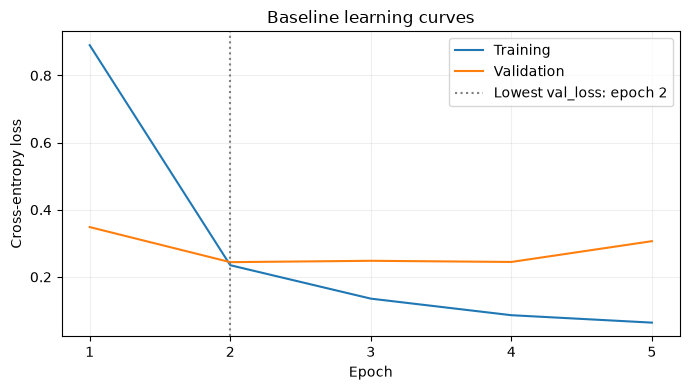

In [19]:
epochs = range(1, len(history.history["loss"]) + 1)
best_epoch = min(epochs, key=lambda epoch: history.history["val_loss"][epoch - 1])

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(epochs, history.history["loss"], label="Training")
ax.plot(epochs, history.history["val_loss"], label="Validation")
ax.axvline(best_epoch, linestyle=":", color="gray", label=f"Lowest val_loss: epoch {best_epoch}")
ax.set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Baseline learning curves")
ax.set_xticks(list(epochs))
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

In [20]:
models_dir = project_root / "models"
models_dir.mkdir(exist_ok=True)

model.save(models_dir / "katakana_baseline.keras")

## Character recall and common confusions

Some Katakana are visually similar, such as ソ/ン and ワ/ウ. To assess whether the model distinguishes them, we examine both recall per character and the most frequent incorrect predictions.

Recall measures the proportion of a character's images that are correctly recognized. For the remaining images, we identify which characters the model predicts instead.

The table below shows the three most frequent confusions for each true character. It reports their frequency among all images of that character and their share of its errors. The error breakdown may therefore help identify systematic confusions hidden by overall accuracy.


In [ ]:
import numpy as np
import pandas as pd

val_ds = build_dataset(
    df_valid,
    batch_size=BATCH_SIZE,
    training=False,
)

probabilities = model.predict(val_ds)
predicted_labels = probabilities.argmax(axis=1)
true_labels = df_valid["label"].to_numpy()

assert len(predicted_labels) == len(true_labels)

characters = np.asarray(unique_char)

results = pd.DataFrame({
    "Actual": characters[true_labels],
    "Predicted": characters[predicted_labels],
})
results["Correct"] = results["Actual"] == results["Predicted"]

# Summary for each true character.
summary = results.groupby("Actual").agg(
    Support=("Correct", "size"),
    Recall=("Correct", "mean"),
)
summary["Errors"] = (
    summary["Support"] * (1 - summary["Recall"])
).round().astype(int)

confusions = (
    results.loc[~results["Correct"]]
    .groupby(["Actual", "Predicted"])
    .size()
    .rename("Count")
    .reset_index()
    .join(summary, on="Actual")
)

confusions["Rate among all examples"] = (
    confusions["Count"] / confusions["Support"]
)
confusions["Share of errors"] = (
    confusions["Count"] / confusions["Errors"]
)

top_confusions = (
    confusions
    .sort_values(
        ["Actual", "Count", "Predicted"],
        ascending=[True, False, True],
    )
    .groupby("Actual", sort=False)
    .head(3)
    .sort_values(
        ["Recall", "Actual", "Count"],
        ascending=[True, True, False],
    )
)

display(
    top_confusions[
        [
            "Actual",
            "Predicted",
            "Support",
            "Recall",
            "Count",
            "Rate among all examples",
            "Share of errors",
        ]
    ]
    .reset_index(drop=True)
    .style
    .format({
        "Recall": "{:.1%}",
        "Rate among all examples": "{:.1%}",
        "Share of errors": "{:.1%}",
    })
    .hide(axis="index")
)

317/317 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


Actual,Predicted,Support,Recall,Count,Rate among all examples,Share of errors
エ,ヱ,211,77.7%,34,16.1%,72.3%
エ,ユ,211,77.7%,3,1.4%,6.4%
エ,シ,211,77.7%,2,0.9%,4.3%
チ,テ,211,85.8%,14,6.6%,46.7%
チ,ネ,211,85.8%,4,1.9%,13.3%
チ,ケ,211,85.8%,3,1.4%,10.0%
ヲ,ラ,211,86.7%,10,4.7%,35.7%
ヲ,ヨ,211,86.7%,6,2.8%,21.4%
ヲ,オ,211,86.7%,2,0.9%,7.1%
テ,ラ,211,87.7%,12,5.7%,46.2%
